# 0. Environment Setup and Reproducibility

This project uses a Conda environment to manage its Python dependencies.

## Installation

1. Clone the project repository and navigate to its root directory:

```bash
git clone https://github.com/Gleisongarcia/Machine-learning-project.git
cd Machine-learning-project
```

2. Create the Conda environment using the provided `environment.yml` file:

```bash
conda env create -f environment.yml
```

3. Activate the environment:

```bash
conda activate smilesproject
```

4. Launch Jupyter:

```bash
jupyter notebook
```

5. Open this notebook and select the `cyp2c19-ml` kernel if necessary.

## Execution

Run all notebook cells in order, from beginning to end. An internet connection may be required to download the dataset.

The `environment.yml` file specifies the Python version and the dependencies required to run the project.


# 1. Problem Definition

## 1.1 Biological Background: Drug Metabolism and CYP2C19

Drug metabolism is a fundamental process in pharmacology. After a drug enters the body, it can be transformed by enzymatic systems that influence its elimination, duration of action and systemic exposure. Among these systems, the cytochrome P450 (CYP) family plays a major role in the metabolism of many therapeutic compounds.

CYP2C19 is one of these enzymes. It is located primarily in the endoplasmic reticulum of liver cells and participates in the metabolism of several drugs, including omeprazole and diazepam. Its activity is therefore relevant to how the body processes certain medications.

An important pharmacological phenomenon is **enzyme inhibition**. When a molecule inhibits CYP2C19, it reduces the enzyme's ability to metabolize its substrates. If another drug depends on this enzyme for its metabolism, inhibition can alter that drug's exposure in the body. Depending on the drugs involved, this may increase the risk of adverse reactions or reduce therapeutic efficacy.

Drug–drug interactions are therefore an important consideration during drug development. Identifying molecules that may inhibit drug-metabolizing enzymes can help researchers characterize potential metabolic interactions at an early stage.

## 1.2 Research Question and Objective

The central question of this project is:

**Can we predict whether a molecule inhibits CYP2C19 from its chemical structure?**

Experimental characterization of drug–enzyme interactions requires laboratory assays. Machine learning offers a complementary approach by learning statistical relationships between molecular representations and experimentally assigned labels.

The objective of this project is to develop and compare machine learning models that predict CYP2C19 inhibition from molecular structure, represented by SMILES strings.

This is a relevant problem because molecular structure influences how a compound interacts with biological targets. However, the relationship between chemical structure and enzyme inhibition is complex and cannot always be captured by simple rules.

## 1.3 Dataset and Prediction Task

This project uses the `CYP2C19_Veith` dataset provided by Therapeutics Data Commons (TDC), based on the work of Veith et al. The dataset contains 12,665 molecules and is designed as a binary classification task.

Each molecule is represented by a SMILES string (*Simplified Molecular Input Line Entry System*), a textual notation that encodes its chemical structure. The model uses this representation to derive numerical features and predict the associated inhibition label.

The target variable is `Y`, defined as follows:

- `Y = 0`: the molecule does not inhibit CYP2C19 according to the dataset label.
- `Y = 1`: the molecule inhibits CYP2C19 according to the dataset label.

The task is therefore to predict one of two classes for each molecule.

## 1.4 Machine Learning Strategy

To investigate how molecular representation affects predictive performance, this project compares two feature engineering approaches:

- **Morgan fingerprints:** fixed-length binary vectors that encode local molecular environments.
- **SMILES character n-grams:** numerical representations based on recurring sequences of characters in SMILES strings.

Both representations will be used to train classification models, including Logistic Regression and Random Forest. Their performance will be compared using appropriate classification metrics, followed by hyperparameter optimization and a final evaluation on a held-out test set.

The aim is to assess which combination of molecular representation and model performs best on this dataset, while critically examining the limitations of the predictions.



# 2. Dataset Description and Exploratory Data Analysis

## 2.1 Dataset Overview

The dataset used in this project is `CYP2C19_Veith`, available through Therapeutics Data Commons (TDC). It contains 12,665 molecules and is designed for the prediction of CYP2C19 inhibition.

Each observation corresponds to a molecule described by three main variables:

- `Drug_ID`: identifier of the molecule.
- `Drug`: molecular structure encoded as a SMILES string.
- `Y`: binary target indicating CYP2C19 inhibition (`0`: non-inhibitor, `1`: inhibitor).

Before training machine learning models, the dataset must be explored to understand its structure, assess data quality and identify potential issues that could affect the analysis.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tdc.single_pred import ADME

# Load the complete dataset
data = ADME(name="CYP2C19_Veith")
df = data.get_data()

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five observations:")
display(df.head())

print("\nData types:")
print(df.dtypes)


Found local copy...
Loading...
Done!


Dataset shape: (12665, 3)

Column names:
['Drug_ID', 'Drug', 'Y']

First five observations:


,Drug_ID,Drug,Y
0,6602638.0,CCCC(=O)Nc1ccc(N2CCN(CC)CC2)c(Cl)c1.Cl,0
1,644675.0,CC(=O)N(c1ccc2oc(=O)sc2c1)S(=O)(=O)c1cccs1,1
2,644851.0,Clc1ccccc1-c1nc(-c2ccccc2)n[nH]1,1
3,644890.0,COc1ccccc1C(c1nnnn1C(C)(C)C)N1CCN(Cc2ccncc2)CC1,1
4,644968.0,COc1ccccc1CNC(=O)Cn1nnc(-c2ccncc2)n1,1



Data types:
Drug_ID    float64
Drug        object
Y            int64
dtype: object



## 2.2 Data Quality and SMILES Validation

Data quality is an important first step because missing values, duplicate observations or invalid molecular representations may affect feature extraction and model training.

SMILES strings will be checked using RDKit, a cheminformatics library that can parse molecular structures from their textual representations.

In [4]:

from rdkit import Chem

# Missing values
print("Missing values per column:")
print(df.isna().sum())

# Duplicate observations
print("\nNumber of duplicated rows:", df.duplicated().sum())

# Duplicate molecule identifiers and SMILES
print("Unique Drug_ID values:", df["Drug_ID"].nunique())
print("Unique SMILES strings:", df["Drug"].nunique())

# Validate SMILES using RDKit
smiles = df["Drug"]

valid_smiles = smiles.apply(
    lambda s: Chem.MolFromSmiles(s) is not None
    if isinstance(s, str) and s.strip()
    else False
)

print("\nSMILES validation:")
print("Valid:", valid_smiles.sum())
print("Invalid:", (~valid_smiles).sum())
print("Validity rate: {:.2f}%".format(valid_smiles.mean() * 100))


Missing values per column:
Drug_ID    0
Drug       0
Y          0
dtype: int64

Number of duplicated rows: 0
Unique Drug_ID values: 12665
Unique SMILES strings: 12665

SMILES validation:
Valid: 12665
Invalid: 0
Validity rate: 100.00%



## 2.3 Target Distribution

The target distribution describes the proportion of inhibitors and non-inhibitors in the dataset. This analysis helps determine whether the classification problem is strongly imbalanced, which can influence model evaluation and the choice of performance metrics.


,Molecule count,Percentage (%)
Y,,
0,6846,54.054481
1,5819,45.945519


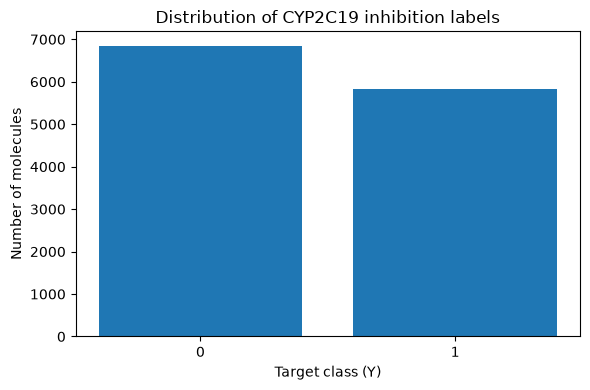

In [5]:

# Count observations in each class
class_counts = df["Y"].value_counts().sort_index()
class_percentages = df["Y"].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "Molecule count": class_counts,
    "Percentage (%)": class_percentages
})

display(target_summary)

# Plot class distribution
plt.figure(figsize=(6, 4))
plt.bar(
    class_counts.index.astype(str),
    class_counts.values
)

plt.xlabel("Target class (Y)")
plt.ylabel("Number of molecules")
plt.title("Distribution of CYP2C19 inhibition labels")
plt.tight_layout()
plt.show()



## 2.4 SMILES Length Distribution

SMILES strings vary in length depending on how molecular structures are encoded. Examining their length distribution provides an overview of the input data and helps identify unusually long representations.

String length should not be interpreted as a direct measure of molecular complexity, since different SMILES strings can encode the same molecular structure.


SMILES length statistics:


count    12665.000000
mean        46.069404
std         19.967456
min          2.000000
25%         35.000000
50%         43.000000
75%         51.000000
max        340.000000
Name: smiles_length, dtype: float64

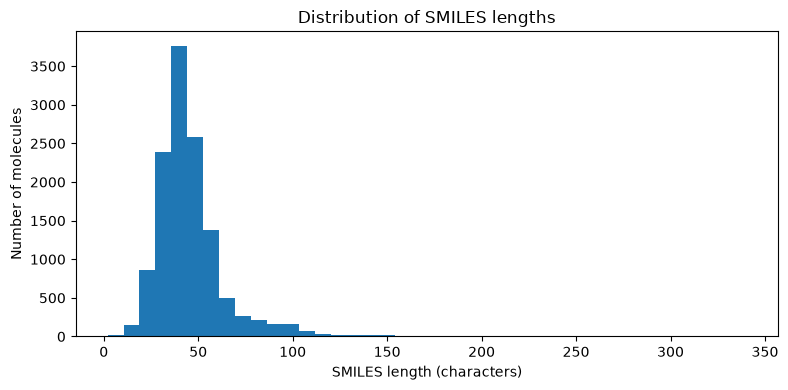

In [6]:

# Calculate SMILES string lengths
df["smiles_length"] = df["Drug"].apply(
    lambda s: len(s) if isinstance(s, str) else np.nan
)

print("SMILES length statistics:")
display(df["smiles_length"].describe())

# Plot overall distribution
plt.figure(figsize=(8, 4))
plt.hist(
    df["smiles_length"].dropna(),
    bins=40
)

plt.xlabel("SMILES length (characters)")
plt.ylabel("Number of molecules")
plt.title("Distribution of SMILES lengths")
plt.tight_layout()
plt.show()



## 2.5 Main Findings

The exploratory analysis provides several observations about the dataset:

- The dataset contains 12,665 molecules described by their identifiers, SMILES strings and binary target labels.
- Data quality was assessed by checking missing values, duplicate observations and SMILES validity.
- The two target classes are relatively balanced, so the classification task does not exhibit a strong class imbalance.
- SMILES string lengths show substantial variability, with some representations considerably longer than the median.

These findings provide the basis for the next step: transforming molecular structures into numerical features suitable for machine learning. Two representations will be investigated: Morgan fingerprints and character n-grams.


## 3. Data Preparation and Feature Engineering

Machine learning algorithms require molecules to be represented as numerical features. However, the dataset describes each molecule using a SMILES string, which is a textual representation of its chemical structure.

In this project, two complementary molecular representations are compared:

1. **Morgan fingerprints**, which encode local molecular environments as a fixed-length binary vector.
2. **SMILES character n-grams**, which encode the presence of short character sequences in the SMILES representation.

To ensure a fair comparison, both representations must use the same training, validation and test molecules.


### 3.1. Train, Validation and Test Split

The dataset is divided into three subsets:

- **Training set (70%)**: used to fit the machine learning models.
- **Validation set (10%)**: used to compare models and select hyperparameters.
- **Test set (20%)**: reserved for the final evaluation of the selected models.

A fixed random seed (`42`) is used to make the random split reproducible. The split must be created once and reused for both molecular representations, ensuring that differences in performance are not caused by evaluating the models on different molecules.

The same target labels are retained across both representations: `0` indicates a non-inhibitor and `1` indicates a CYP2C19 inhibitor.


In [7]:
splits = data.get_split(
    method="random",
    seed=42,
    frac=[0.7, 0.1, 0.2]
)

train_df = splits["train"].copy()
valid_df = splits["valid"].copy()
test_df = splits["test"].copy()

print("Train:", train_df.shape)
print("Validation:", valid_df.shape)
print("Test:", test_df.shape)

Train: (8866, 3)
Validation: (1266, 3)
Test: (2533, 3)


### 3.2. Molecular Representation 1: Morgan Fingerprints

Morgan fingerprints represent molecules through their local chemical environments. Starting from each atom, the algorithm identifies neighboring atoms and bonds within a specified radius and converts these environments into a fixed-length fingerprint.

In this project, Morgan fingerprints are generated using **radius 2** and **2048 bits**.

Each molecule is represented by a binary vector of length 2048:

- `1` indicates that at least one molecular environment is mapped to the corresponding bit.
- `0` indicates that no environment is mapped to that bit.

**Why this representation?**

Morgan fingerprints are widely used in cheminformatics because they provide a compact numerical description of molecular structure. They encode information about local atomic environments without requiring the model to process a textual string directly.

The fixed-length representation is suitable for classical machine learning algorithms such as Logistic Regression and Random Forest. However, because the environments are hashed into a limited number of bits, different environments can occasionally map to the same bit.


In [8]:
import numpy as np
from rdkit import Chem
from rdkit.Chem import AllChem

def smiles_to_morgan(smiles, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        raise ValueError(f"Invalid SMILES: {smiles}")

    fp = AllChem.GetMorganFingerprintAsBitVect(
        mol,
        radius=radius,
        nBits=n_bits
    )

    return np.asarray(fp, dtype=np.uint8)

X_train_morgan = np.stack(
    train_df["Drug"].map(smiles_to_morgan).to_numpy()
)
X_valid_morgan = np.stack(
    valid_df["Drug"].map(smiles_to_morgan).to_numpy()
)
X_test_morgan = np.stack(
    test_df["Drug"].map(smiles_to_morgan).to_numpy()
)

y_train = train_df["Y"].to_numpy()
y_valid = valid_df["Y"].to_numpy()
y_test = test_df["Y"].to_numpy()

print("Morgan train:", X_train_morgan.shape)
print("Morgan validation:", X_valid_morgan.shape)
print("Morgan test:", X_test_morgan.shape)

Morgan train: (8866, 2048)
Morgan validation: (1266, 2048)
Morgan test: (2533, 2048)


<div style="display: flex; gap: 15px;">
  <img src="../figures/figures_fingerprints/active_bits_distribution.png" width="48%">
  <img src="../figures/figures_fingerprints/morgan_bit_314.png" width="48%">
</div>

### 3.3. Molecular Representation 2: SMILES Character N-grams

The second approach represents each molecule through character n-grams extracted from its SMILES string.

An n-gram is a consecutive sequence of characters. In this project, character sequences of lengths 2 to 4 are considered. For example, a SMILES string such as `CCO` contains the 2-grams `CC` and `CO`, as well as the 3-gram `CCO`.

A `CountVectorizer` is used with the following settings:

- `analyzer="char"`: extracts character sequences rather than words.
- `ngram_range=(2, 4)`: considers sequences of 2, 3 and 4 characters.
- `min_df=2`: excludes n-grams appearing in fewer than two documents in the training data.
- `max_features=30000`: sets an upper limit on the vocabulary size.
- `binary=True`: records whether an n-gram is present, rather than how many times it occurs.

The vocabulary is learned from the training set only. The same fitted vectorizer is then applied to the validation and test sets.

**Why this representation?**

SMILES n-grams provide a complementary approach to Morgan fingerprints. Instead of explicitly constructing local molecular environments, they learn patterns from the character sequences used to encode chemical structures.

This makes the approach straightforward to implement with standard text-processing tools. However, SMILES strings are not natural language, and character sequences do not always correspond directly to chemically meaningful substructures. Results can also depend on the chosen SMILES representation.


In [9]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(
    analyzer="char",
    ngram_range=(2, 4),
    min_df=2,
    max_features=30000,
    binary=True,
    dtype=np.float32
)

X_train_text = vectorizer.fit_transform(train_df["Drug"])
X_valid_text = vectorizer.transform(valid_df["Drug"])
X_test_text = vectorizer.transform(test_df["Drug"])

print("SMILES n-grams")
print("Vocabulary size:", len(vectorizer.vocabulary_))
print("Train:", X_train_text.shape)
print("Validation:", X_valid_text.shape)
print("Test:", X_test_text.shape)

SMILES n-grams
Vocabulary size: 5123
Train: (8866, 5123)
Validation: (1266, 5123)
Test: (2533, 5123)


<div style="display: flex; gap: 15px;">
  <img src="../figures/figures_text/text_active_ngrams_distribution.png" width="48%">
  <img src="../figures/figures_text/text_frequent_ngrams.png" width="48%">
</div>

### 3.4. Comparison of Molecular Representations

Both approaches encode the same molecules but describe their structures differently.

| Property | Morgan fingerprints | SMILES character n-grams |
|---|---|---|
| Input | SMILES converted into molecular graphs | SMILES strings |
| Feature extraction | Local atomic environments | Consecutive character sequences |
| Feature representation | Binary vector | Binary n-gram presence vector |
| Feature dimension | 2048 | Learned vocabulary size |
| Main advantage | Compact representation of local chemical environments | Simple, data-driven extraction of textual patterns |
| Main limitation | Hash collisions may occur | Character patterns do not always correspond to meaningful chemical substructures |

For Morgan fingerprints, each column represents a hashed molecular-environment bit. For SMILES n-grams, each column represents a character sequence in the learned vocabulary.

The rows correspond to molecules, so both approaches can be evaluated using the same train, validation and test partitions. This enables a more controlled comparison of their predictive performance.


In [10]:
print("Number of molecules")
print("Train:", len(y_train))
print("Validation:", len(y_valid))
print("Test:", len(y_test))

print("\nMorgan fingerprints")
print("Train:", X_train_morgan.shape)
print("Validation:", X_valid_morgan.shape)
print("Test:", X_test_morgan.shape)

print("\nSMILES n-grams")
print("Train:", X_train_text.shape)
print("Validation:", X_valid_text.shape)
print("Test:", X_test_text.shape)

Number of molecules
Train: 8866
Validation: 1266
Test: 2533

Morgan fingerprints
Train: (8866, 2048)
Validation: (1266, 2048)
Test: (2533, 2048)

SMILES n-grams
Train: (8866, 5123)
Validation: (1266, 5123)
Test: (2533, 5123)


### Distribution of molecular features

To better understand the two molecular representations, we examine the distribution of the number of active features per molecule.

For Morgan fingerprints, this corresponds to the number of active bits among the 2,048 available positions. For SMILES character n-grams, it corresponds to the number of distinct n-grams present in each molecule's representation.

These histograms help us understand how many features are typically used to represent a molecule and how much this number varies across the dataset. However, the two quantities are not directly comparable because they are based on different feature-generation methods.

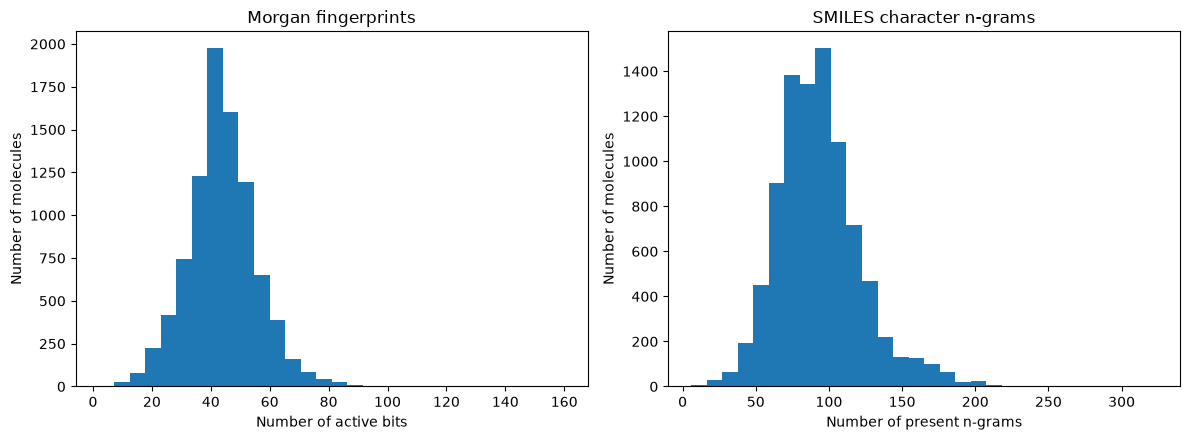

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse

# Count active features per molecule
morgan_active = np.asarray(X_train_morgan.sum(axis=1)).ravel()

text_active = np.asarray(
    X_train_text.getnnz(axis=1)
    if sparse.issparse(X_train_text)
    else np.count_nonzero(X_train_text, axis=1)
).ravel()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(morgan_active, bins=30)
axes[0].set_title("Morgan fingerprints")
axes[0].set_xlabel("Number of active bits")
axes[0].set_ylabel("Number of molecules")

axes[1].hist(text_active, bins=30)
axes[1].set_title("SMILES character n-grams")
axes[1].set_xlabel("Number of present n-grams")
axes[1].set_ylabel("Number of molecules")

plt.tight_layout()
plt.show()

## 4. Baseline Models

Before optimizing the models, we establish baseline performance using two machine learning algorithms and two molecular representations.

**Logistic Regression** is a linear classification model that estimates the probability of a molecule belonging to a given class. It provides a simple and interpretable baseline for evaluating whether the molecular features contain useful predictive information.

**Random Forest** combines multiple decision trees. Each tree makes a prediction, and their predictions are aggregated to produce the final classification. It can capture nonlinear relationships and interactions between features.

We evaluate both algorithms using Morgan fingerprints and SMILES character n-grams. This allows us to compare the predictive value of chemically oriented structural fingerprints with features extracted directly from the SMILES representation.

The models are initially trained with fixed, baseline hyperparameters. Hyperparameter optimization is performed later, allowing us to assess whether tuning improves performance.

### 4.1 Evaluation metrics

We evaluate the models on the validation set using six complementary metrics:

- **Accuracy:** proportion of all predictions that are correct.
- **Balanced accuracy:** average recall across the two classes, giving equal importance to each class.
- **Precision:** proportion of predicted inhibitors that are actual inhibitors.
- **Recall:** proportion of actual inhibitors correctly identified by the model.
- **F1-score:** harmonic mean of precision and recall.
- **ROC-AUC:** measures the model's ability to rank inhibitors above non-inhibitors across different classification thresholds.

The positive class is defined as **Y = 1 (CYP2C19 inhibitor)**, while Y = 0 represents non-inhibitors.

Accuracy alone may not fully describe model performance. Therefore, we examine balanced accuracy, precision, recall, F1-score and ROC-AUC together.

In [12]:

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Define baseline models
models = {
    "Morgan - Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=42),
        X_train_morgan, X_valid_morgan
    ),
    "Morgan - Random Forest": (
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ),
        X_train_morgan, X_valid_morgan
    ),
    "SMILES n-grams - Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=42),
        X_train_text, X_valid_text
    ),
    "SMILES n-grams - Random Forest": (
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ),
        X_train_text, X_valid_text
    )
}

results = []

for name, (model, X_train, X_valid) in models.items():
    # Train the model
    model.fit(X_train, y_train)

    # Predict classes and probabilities on validation data
    y_pred = model.predict(X_valid)
    y_proba = model.predict_proba(X_valid)[:, 1]

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_valid, y_pred),
        "Precision": precision_score(y_valid, y_pred, zero_division=0),
        "Recall": recall_score(y_valid, y_pred, zero_division=0),
        "F1-score": f1_score(y_valid, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_valid, y_proba)
    })

baseline_results = pd.DataFrame(results).set_index("Model")

baseline_results.round(3)


,Accuracy,Balanced accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,,
Morgan - Logistic Regression,0.795,0.794,0.783,0.777,0.780,0.859
Morgan - Random Forest,0.793,0.795,0.759,0.818,0.787,0.881
SMILES n-grams - Logistic Regression,0.782,0.781,0.772,0.759,0.765,0.854
SMILES n-grams - Random Forest,0.806,0.808,0.769,0.838,0.802,0.875


### 4.2 Initial results and interpretation

The baseline results show that performance depends on both the molecular representation and the classification algorithm.

**Random Forest with SMILES character n-grams achieves the highest accuracy (0.806), balanced accuracy (0.808), recall (0.838) and F1-score (0.802).** This suggests that the combination of a nonlinear classifier and features extracted directly from SMILES is effective at identifying CYP2C19 inhibitors.

Morgan fingerprints combined with Random Forest achieve the highest ROC-AUC (0.881), compared with 0.875 for SMILES n-grams with Random Forest. This indicates a slightly better ability to distinguish between inhibitors and non-inhibitors across different classification thresholds, although the difference is small.

The two Random Forest models achieve higher recall than their corresponding Logistic Regression models. In particular, the SMILES n-gram model identifies 83.8% of actual inhibitors, compared with 75.9% for Logistic Regression using the same representation. However, higher recall does not necessarily mean fewer false positives, so precision must also be considered.

Logistic Regression provides a useful linear baseline, but its performance is lower than that of Random Forest in terms of accuracy, recall and F1-score for both representations. This suggests that nonlinear relationships between the molecular features and CYP2C19 inhibition may be useful for prediction.

Overall, these results provide a baseline for the next stage of the project. Hyperparameter optimization will investigate whether the models can achieve better performance. The final test set will remain reserved for an unbiased evaluation of the selected model.

## 5. Hyperparameter Optimization

In the previous section, we established four baseline models by combining two molecular representations (Morgan fingerprints and SMILES character n-grams) with two classification algorithms (Logistic Regression and Random Forest).

The goal of this section is to investigate whether their performance can be improved by optimizing both the molecular representation and the classifier.

We will explore the following parameters:

- **Morgan fingerprints:** radius and fingerprint size.
- **SMILES character n-grams:** n-gram length, minimum document frequency, maximum vocabulary size, and binary versus count-based features.
- **Classification algorithms:** selected hyperparameters of Logistic Regression and Random Forest.

We will use five-fold cross-validation on the training set to compare configurations. The ROC-AUC score will be the primary selection metric, while other classification metrics will be considered during subsequent evaluation.

The validation set will remain available for an additional comparison of selected configurations. The test set will not be used for hyperparameter selection and will be reserved for the final evaluation.

To avoid data leakage, each SMILES vectorizer will be fitted separately within each training fold, rather than using a vocabulary learned from the entire training set.

In [13]:
import numpy as np
import pandas as pd

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from rdkit import DataStructs

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Extract raw SMILES strings and labels from the training set
smiles_train = train_df["Drug"].tolist()


assert len(smiles_train) == len(y_train)

print(f"Training molecules: {len(smiles_train)}")
print(f"Cross-validation folds: {cv.get_n_splits()}")

Training molecules: 8866
Cross-validation folds: 5


In [14]:
import os, json, gc, joblib
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator, DataStructs
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

SEED = 42
SCORING = "roc_auc"
N_SPLITS = 5
FOLDS_PATH = "cv_folds.pkl"
FP_CACHE_DIR = "fp_cache"
os.makedirs(FP_CACHE_DIR, exist_ok=True)

# Folds generados UNA sola vez y reutilizados por LR y RF → comparabilidad garantizada
if os.path.exists(FOLDS_PATH):
    folds = joblib.load(FOLDS_PATH)
    print(f"Folds cargados desde {FOLDS_PATH}")
else:
    cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    folds = list(cv.split(np.zeros(len(y_train)), y_train))
    joblib.dump(folds, FOLDS_PATH)
    print(f"Folds generados y guardados en {FOLDS_PATH}")

print(f"n_splits={len(folds)}, tamaños de validación: {[len(v) for _, v in folds]}")

Folds generados y guardados en cv_folds.pkl
n_splits=5, tamaños de validación: [1774, 1773, 1773, 1773, 1773]


In [15]:
def generate_morgan_fingerprints(smiles, radius, n_bits):
    generator = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=n_bits)
    fps = np.zeros((len(smiles), n_bits), dtype=np.uint8)
    for i, smi in enumerate(smiles):
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            raise ValueError(f"Invalid SMILES at index {i}: {smi}")
        fp = generator.GetFingerprint(mol)
        DataStructs.ConvertToNumpyArray(fp, fps[i])
    return fps

def get_fingerprints(smiles, radius, n_bits, prefix="train"):
    path = os.path.join(FP_CACHE_DIR, f"{prefix}_morgan_r{radius}_b{n_bits}.pkl")
    if os.path.exists(path):
        return joblib.load(path)
    X = generate_morgan_fingerprints(smiles, radius, n_bits)
    joblib.dump(X, path)
    return X

In [16]:
def append_result(path, record):
    data = json.load(open(path)) if os.path.exists(path) else []
    data.append(record)
    json.dump(data, open(path, "w"), indent=2)

def already_done(path, key_dict):
    if not os.path.exists(path):
        return False
    data = json.load(open(path))
    return any(all(r.get(k) == v for k, v in key_dict.items()) for r in data)

RADII = [1, 2, 3]
BIT_SIZES = [1024, 2048, 4096]

In [18]:
LR_RESULTS = "results_lr.json"
lr_grid = {"C": [0.1, 1.0, 10.0]}

for radius in RADII:
    for n_bits in BIT_SIZES:
        key = {"Radius": radius, "Fingerprint size": n_bits, "Model": "Logistic Regression"}
        if already_done(LR_RESULTS, key):
            print(f"Skip LR r={radius} b={n_bits} (ya hecho)")
            continue
        print(f"LR: radius={radius}, n_bits={n_bits}")
        X = get_fingerprints(smiles_train, radius, n_bits, prefix="train")
        search = GridSearchCV(
            LogisticRegression(max_iter=2000, random_state=SEED),
            lr_grid,
            scoring=SCORING,
            cv=folds,
            n_jobs=-1,
            refit=False,          # no guardamos el modelo, solo score/params
        )
        search.fit(X, y_train)
        record = {
            "Representation": "Morgan",
            "Radius": radius,
            "Fingerprint size": n_bits,
            "Model": "Logistic Regression",
            "Best CV ROC-AUC": float(search.best_score_),
            "Best parameters": search.best_params_,
        }
        append_result(LR_RESULTS, record)
        print(f"  best={search.best_score_:.4f}  params={search.best_params_}")
        del X, search          # libera memoria
        gc.collect()

pd.DataFrame(json.load(open(LR_RESULTS))).sort_values(
    "Best CV ROC-AUC", ascending=False
).reset_index(drop=True)

LR: radius=1, n_bits=1024


/home/gleison/miniconda3/envs/projectmolecules/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/home/gleison/miniconda3/envs/projectmolecules/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/home/gleison/miniconda3/envs/projectmolecules/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as e

  best=0.8641  params={'C': 0.1}
LR: radius=1, n_bits=2048
  best=0.8681  params={'C': 0.1}
LR: radius=1, n_bits=4096
  best=0.8714  params={'C': 0.1}
LR: radius=2, n_bits=1024
  best=0.8620  params={'C': 0.1}
LR: radius=2, n_bits=2048
  best=0.8757  params={'C': 0.1}
LR: radius=2, n_bits=4096
  best=0.8845  params={'C': 0.1}
LR: radius=3, n_bits=1024
  best=0.8452  params={'C': 0.1}
LR: radius=3, n_bits=2048
  best=0.8643  params={'C': 0.1}
LR: radius=3, n_bits=4096
  best=0.8795  params={'C': 0.1}


,Representation,Radius,Fingerprint size,Model,Best CV ROC-AUC,Best parameters
0,Morgan,2,4096,Logistic Regression,0.884514,{'C': 0.1}
1,Morgan,3,4096,Logistic Regression,0.879474,{'C': 0.1}
2,Morgan,2,2048,Logistic Regression,0.875698,{'C': 0.1}
3,Morgan,1,4096,Logistic Regression,0.871420,{'C': 0.1}
4,Morgan,1,2048,Logistic Regression,0.868065,{'C': 0.1}
5,Morgan,3,2048,Logistic Regression,0.864262,{'C': 0.1}
6,Morgan,1,1024,Logistic Regression,0.864119,{'C': 0.1}
7,Morgan,2,1024,Logistic Regression,0.861950,{'C': 0.1}
8,Morgan,3,1024,Logistic Regression,0.845164,{'C': 0.1}


In [20]:
RF_RESULTS = "results_rf.json"
rf_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 15],
    "min_samples_leaf": [2, 5],
}

for radius in RADII:
    for n_bits in BIT_SIZES:
        key = {"Radius": radius, "Fingerprint size": n_bits, "Model": "Random Forest"}
        if already_done(RF_RESULTS, key):
            print(f"Skip RF r={radius} b={n_bits} (ya hecho)")
            continue
        print(f"RF: radius={radius}, n_bits={n_bits}")
        X = get_fingerprints(smiles_train, radius, n_bits, prefix="train")
        search = GridSearchCV(
            RandomForestClassifier(random_state=SEED, n_jobs=1),  # n_jobs=1 dentro, -1 fuera
            rf_grid,
            scoring=SCORING,
            cv=folds,
            n_jobs=-1,
            refit=False,
        )
        search.fit(X, y_train)
        record = {
            "Representation": "Morgan",
            "Radius": radius,
            "Fingerprint size": n_bits,
            "Model": "Random Forest",
            "Best CV ROC-AUC": float(search.best_score_),
            "Best parameters": search.best_params_,
        }
        append_result(RF_RESULTS, record)
        print(f"  best={search.best_score_:.4f}  params={search.best_params_}")
        del X, search
        gc.collect()

pd.DataFrame(json.load(open(RF_RESULTS))).sort_values(
    "Best CV ROC-AUC", ascending=False
).reset_index(drop=True)

RF: radius=1, n_bits=1024
  best=0.8698  params={'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}
RF: radius=1, n_bits=2048
  best=0.8698  params={'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}
RF: radius=1, n_bits=4096
  best=0.8681  params={'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}
RF: radius=2, n_bits=1024
  best=0.8674  params={'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}
RF: radius=2, n_bits=2048
  best=0.8724  params={'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}
RF: radius=2, n_bits=4096
  best=0.8767  params={'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}
RF: radius=3, n_bits=1024
  best=0.8638  params={'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}
RF: radius=3, n_bits=2048
  best=0.8691  params={'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}
RF: radius=3, n_bits=4096
  best=0.8742  params={'max_depth': None, 'min_samples_leaf': 2, 'n_estimators

,Representation,Radius,Fingerprint size,Model,Best CV ROC-AUC,Best parameters
0,Morgan,2,4096,Random Forest,0.876677,"{'max_depth': None, 'min_samples_leaf': 2, 'n_..."
1,Morgan,3,4096,Random Forest,0.874225,"{'max_depth': None, 'min_samples_leaf': 2, 'n_..."
2,Morgan,2,2048,Random Forest,0.872434,"{'max_depth': None, 'min_samples_leaf': 2, 'n_..."
3,Morgan,1,1024,Random Forest,0.869804,"{'max_depth': None, 'min_samples_leaf': 2, 'n_..."
4,Morgan,1,2048,Random Forest,0.869781,"{'max_depth': None, 'min_samples_leaf': 2, 'n_..."
5,Morgan,3,2048,Random Forest,0.869087,"{'max_depth': None, 'min_samples_leaf': 2, 'n_..."
6,Morgan,1,4096,Random Forest,0.868117,"{'max_depth': None, 'min_samples_leaf': 2, 'n_..."
7,Morgan,2,1024,Random Forest,0.867447,"{'max_depth': None, 'min_samples_leaf': 2, 'n_..."
8,Morgan,3,1024,Random Forest,0.863788,"{'max_depth': None, 'min_samples_leaf': 2, 'n_..."


In [21]:
all_results = pd.concat([
    pd.DataFrame(json.load(open(LR_RESULTS))),
    pd.DataFrame(json.load(open(RF_RESULTS))),
]).sort_values("Best CV ROC-AUC", ascending=False).reset_index(drop=True)

# Mejor configuración global
best_overall = all_results.iloc[0]
print("Mejor configuración global:")
print(best_overall.to_dict())

all_results

Mejor configuración global:
{'Representation': 'Morgan', 'Radius': 2, 'Fingerprint size': 4096, 'Model': 'Logistic Regression', 'Best CV ROC-AUC': 0.8845140375165048, 'Best parameters': {'C': 0.1}}


,Representation,Radius,Fingerprint size,Model,Best CV ROC-AUC,Best parameters
0,Morgan,2,4096,Logistic Regression,0.884514,{'C': 0.1}
1,Morgan,3,4096,Logistic Regression,0.879474,{'C': 0.1}
2,Morgan,2,4096,Random Forest,0.876677,"{'max_depth': None, 'min_samples_leaf': 2, 'n_..."
3,Morgan,2,2048,Logistic Regression,0.875698,{'C': 0.1}
4,Morgan,3,4096,Random Forest,0.874225,"{'max_depth': None, 'min_samples_leaf': 2, 'n_..."
5,Morgan,2,2048,Random Forest,0.872434,"{'max_depth': None, 'min_samples_leaf': 2, 'n_..."
6,Morgan,1,4096,Logistic Regression,0.871420,{'C': 0.1}
7,Morgan,1,1024,Random Forest,0.869804,"{'max_depth': None, 'min_samples_leaf': 2, 'n_..."
8,Morgan,1,2048,Random Forest,0.869781,"{'max_depth': None, 'min_samples_leaf': 2, 'n_..."
9,Morgan,3,2048,Random Forest,0.869087,"{'max_depth': None, 'min_samples_leaf': 2, 'n_..."


In [24]:
import os, json, gc, joblib
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

SEED = 42
SCORING = "roc_auc"
FOLDS_PATH = "cv_folds.pkl"

# Reuse EXACTLY the same folds as in Morgan → ensures comparability across representations
folds = joblib.load(FOLDS_PATH)
print(f"Folds loaded: {len(folds)} splits, validation sizes: {[len(v) for _, v in folds]}")

TEXT_VECTORIZER_DIST = {
    "vectorizer__ngram_range": [(2, 3), (2, 4), (3, 5)],
    "vectorizer__min_df": [1, 2, 5],
    "vectorizer__max_features": [10000, 30000],
    "vectorizer__binary": [True, False],
}

def make_pipeline(classifier):
    return Pipeline([
        ("vectorizer", CountVectorizer(analyzer="char", dtype=np.float32)),
        ("classifier", classifier),
    ])

def append_result(path, record):
    data = json.load(open(path)) if os.path.exists(path) else []
    data.append(record)
    json.dump(data, open(path, "w"), indent=2)

def already_done(path, key_dict):
    if not os.path.exists(path):
        return False
    data = json.load(open(path))
    return any(all(r.get(k) == v for k, v in key_dict.items()) for r in data)

Folds loaded: 5 splits, validation sizes: [1774, 1773, 1773, 1773, 1773]


In [32]:
LR_TEXT_RESULTS = "results_text_lr.json"

TEXT_REPRESENTATIONS = [
    {"ngram_range": nr, "min_df": md, "max_features": mf, "binary": b}
    for nr in [(2, 3), (2, 4), (3, 5)]
    for md in [1, 2, 5]
    for mf in [10000, 30000]
    for b in [True, False]
]

lr_classifier_dist = {"classifier__C": [0.1, 1.0, 10.0]}

for rep in TEXT_REPRESENTATIONS:
    key = {
        "Representation": "SMILES char n-grams",
        "ngram_range": rep["ngram_range"],
        "min_df": rep["min_df"],
        "max_features": rep["max_features"],
        "binary": rep["binary"],
        "Model": "Logistic Regression",
    }
    if already_done(LR_TEXT_RESULTS, key):
        print(f"Skip LR text {rep}")
        continue

    pipe = Pipeline([
        ("vectorizer", CountVectorizer(
            analyzer="char", dtype=np.float32,
            ngram_range=rep["ngram_range"],
            min_df=rep["min_df"],
            max_features=rep["max_features"],
            binary=rep["binary"],
        )),
        ("classifier", LogisticRegression(max_iter=2000, random_state=SEED)),
    ])

    search = GridSearchCV(
        pipe, lr_classifier_dist,
        scoring=SCORING, cv=folds, n_jobs=-1, refit=False,
    )
    search.fit(smiles_train, y_train)

    append_result(LR_TEXT_RESULTS, {
        **key,
        "Best CV ROC-AUC": float(search.best_score_),
        "Best parameters": search.best_params_,
    })
    print(f"LR text {rep} → {search.best_score_:.4f}")
    del search, pipe; gc.collect()

pd.DataFrame(json.load(open(LR_TEXT_RESULTS))).sort_values(
    "Best CV ROC-AUC", ascending=False
).reset_index(drop=True)

/home/gleison/miniconda3/envs/projectmolecules/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/home/gleison/miniconda3/envs/projectmolecules/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/home/gleison/miniconda3/envs/projectmolecules/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as e

LR text {'ngram_range': (2, 3), 'min_df': 1, 'max_features': 10000, 'binary': True} → 0.8413
LR text {'ngram_range': (2, 3), 'min_df': 1, 'max_features': 10000, 'binary': False} → 0.8492
LR text {'ngram_range': (2, 3), 'min_df': 1, 'max_features': 30000, 'binary': True} → 0.8413
LR text {'ngram_range': (2, 3), 'min_df': 1, 'max_features': 30000, 'binary': False} → 0.8492
LR text {'ngram_range': (2, 3), 'min_df': 2, 'max_features': 10000, 'binary': True} → 0.8413
LR text {'ngram_range': (2, 3), 'min_df': 2, 'max_features': 10000, 'binary': False} → 0.8492
LR text {'ngram_range': (2, 3), 'min_df': 2, 'max_features': 30000, 'binary': True} → 0.8413
LR text {'ngram_range': (2, 3), 'min_df': 2, 'max_features': 30000, 'binary': False} → 0.8492
LR text {'ngram_range': (2, 3), 'min_df': 5, 'max_features': 10000, 'binary': True} → 0.8411
LR text {'ngram_range': (2, 3), 'min_df': 5, 'max_features': 10000, 'binary': False} → 0.8490
LR text {'ngram_range': (2, 3), 'min_df': 5, 'max_features': 3000

,Representation,Model,Best CV ROC-AUC,Best parameters,ngram_range,min_df,max_features,binary
0,SMILES char n-grams,Logistic Regression,0.863671,{'classifier__C': 0.1},"[3, 5]",1.0,30000.0,False
1,SMILES char n-grams,Logistic Regression,0.863574,{'classifier__C': 0.1},"[3, 5]",2.0,30000.0,False
2,SMILES char n-grams,Logistic Regression,0.863429,{'classifier__C': 0.1},"[3, 5]",5.0,30000.0,False
3,SMILES char n-grams,Logistic Regression,0.863429,{'classifier__C': 0.1},"[3, 5]",5.0,10000.0,False
4,SMILES char n-grams,Logistic Regression,0.863385,{'classifier__C': 0.1},"[3, 5]",1.0,10000.0,False
5,SMILES char n-grams,Logistic Regression,0.863355,{'classifier__C': 0.1},"[3, 5]",2.0,10000.0,False
6,SMILES char n-grams,Logistic Regression,0.861759,"{'vectorizer__ngram_range': [3, 5], 'vectorize...",NaN,NaN,NaN,NaN
7,SMILES char n-grams,Logistic Regression,0.861759,{'classifier__C': 0.1},"[3, 5]",1.0,30000.0,True
8,SMILES char n-grams,Logistic Regression,0.861671,{'classifier__C': 0.1},"[3, 5]",2.0,30000.0,True
9,SMILES char n-grams,Logistic Regression,0.861473,{'classifier__C': 0.1},"[3, 5]",2.0,10000.0,True


In [29]:
RF_TEXT_RESULTS = "results_text_rf.json"

# Reduced max_features and limited n_jobs: RF on sparse text is memory-hungry
rf_classifier_dist = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 15],
    "classifier__min_samples_leaf": [1, 2],
}
rf_param_dist = {**TEXT_VECTORIZER_DIST, **rf_classifier_dist}

key = {"Representation": "SMILES char n-grams", "Model": "Random Forest"}

if not already_done(RF_TEXT_RESULTS, key):
    search = RandomizedSearchCV(
        estimator=make_pipeline(RandomForestClassifier(random_state=SEED, n_jobs=1)),
        param_distributions=rf_param_dist,
        n_iter=20,
        scoring=SCORING,
        cv=folds,
        random_state=SEED,
        n_jobs=2,                  # limited on purpose: each worker may densify large matrices
        refit=False,
        return_train_score=False,
    )
    search.fit(smiles_train, y_train)

    append_result(RF_TEXT_RESULTS, {
        **key,
        "Best CV ROC-AUC": float(search.best_score_),
        "Best parameters": search.best_params_,
    })
    print(f"RF text → best={search.best_score_:.4f} params={search.best_params_}")

    del search
    gc.collect()
else:
    print("RF text already done, skipping")

pd.DataFrame(json.load(open(RF_TEXT_RESULTS))).sort_values(
    "Best CV ROC-AUC", ascending=False
).reset_index(drop=True)

/home/gleison/miniconda3/envs/projectmolecules/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/home/gleison/miniconda3/envs/projectmolecules/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)


RF text → best=0.8708 params={'vectorizer__ngram_range': (3, 5), 'vectorizer__min_df': 1, 'vectorizer__max_features': 10000, 'vectorizer__binary': False, 'classifier__n_estimators': 200, 'classifier__min_samples_leaf': 1, 'classifier__max_depth': None}


,Representation,Model,Best CV ROC-AUC,Best parameters
0,SMILES char n-grams,Random Forest,0.870821,"{'vectorizer__ngram_range': [3, 5], 'vectorize..."


In [34]:
all_results = (
    pd.concat([
        pd.DataFrame(json.load(open("results_lr.json"))),
        pd.DataFrame(json.load(open("results_rf.json"))),
        pd.DataFrame(json.load(open(LR_TEXT_RESULTS))),
        pd.DataFrame(json.load(open(RF_TEXT_RESULTS))),
    ])
    .sort_values("Best CV ROC-AUC", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

all_results

,Representation,Radius,Fingerprint size,Model,Best CV ROC-AUC,Best parameters,ngram_range,min_df,max_features,binary
0,Morgan,2.0,4096.0,Logistic Regression,0.884514,{'C': 0.1},NaN,NaN,NaN,NaN
1,Morgan,3.0,4096.0,Logistic Regression,0.879474,{'C': 0.1},NaN,NaN,NaN,NaN
2,Morgan,2.0,4096.0,Random Forest,0.876677,"{'max_depth': None, 'min_samples_leaf': 2, 'n_...",NaN,NaN,NaN,NaN
3,Morgan,2.0,2048.0,Logistic Regression,0.875698,{'C': 0.1},NaN,NaN,NaN,NaN
4,Morgan,3.0,4096.0,Random Forest,0.874225,"{'max_depth': None, 'min_samples_leaf': 2, 'n_...",NaN,NaN,NaN,NaN
5,Morgan,2.0,2048.0,Random Forest,0.872434,"{'max_depth': None, 'min_samples_leaf': 2, 'n_...",NaN,NaN,NaN,NaN
6,Morgan,1.0,4096.0,Logistic Regression,0.871420,{'C': 0.1},NaN,NaN,NaN,NaN
7,SMILES char n-grams,NaN,NaN,Random Forest,0.870821,"{'vectorizer__ngram_range': [3, 5], 'vectorize...",NaN,NaN,NaN,NaN
8,Morgan,1.0,1024.0,Random Forest,0.869804,"{'max_depth': None, 'min_samples_leaf': 2, 'n_...",NaN,NaN,NaN,NaN
9,Morgan,1.0,2048.0,Random Forest,0.869781,"{'max_depth': None, 'min_samples_leaf': 2, 'n_...",NaN,NaN,NaN,NaN


## 7. Obstacles encountered and solutions

Two obstacles had a decisive impact on the hyperparameter optimization stage
(Section 5). Both were resolved and the final results depend on the fixes
described below.

---

### 7.1. Kernel crashes during long optimization runs (memory exhaustion)

**Problem.** The optimization loops consistently killed the Jupyter kernel in
VS Code after roughly 10 minutes, with no Python traceback — the kernel simply
disappeared. Running `dmesg | grep -i "killed process"` inside WSL confirmed
the OOM (Out-Of-Memory) killer was terminating the Python process.

**Root cause.** Two memory-hungry patterns in the original code:

1. Each fitted `GridSearchCV` object was stored in a dictionary with
   `refit=True`, keeping a fully trained Random Forest (up to 300 trees of
   depth 20 over 9,600 × 4,096 features) in memory for every `radius × n_bits`
   combination. This accumulated several GB that were never released.
2. `n_jobs=-1` was used for Random Forest on sparse text matrices. Some
   scikit-learn versions densify sparse inputs internally, so each worker
   could allocate ~2 GB, and 8 parallel workers pushed peak memory to ~18 GB.

**Solution.** The loop was refactored to keep only what is actually needed:

- Removed the `searches` dictionary entirely; only `best_score_` and
  `best_params_` are stored per combination.
- Set `refit=False` during tuning. The best estimator is re-fitted once, at
  the end, for the final model only.
- Explicit `del X, search; gc.collect()` after each iteration.
- Limited `n_jobs` to `2` (or `1`) for Random Forest on sparse text;
  Logistic Regression keeps `n_jobs=-1` since it handles sparse data natively.
- Added JSON checkpointing (`append_result` + `already_done`) so a crash does
  not lose progress and the loop resumes where it stopped.
- Cached Morgan fingerprints to disk, since they depend only on the molecule
  and its parameters, not on the fold.

**Result.** The Random Forest loop completed without triggering the OOM killer,
and `free -h` showed a stable memory profile across iterations.

---

### 7.2. Data leakage when vectorizing text features

**Problem.** Text features required special care during cross-validation.
`CountVectorizer` learns a vocabulary from the data it is fitted on. Vectorizing
the whole training set once and then splitting into CV folds would leak
information from the validation fold into the vocabulary, producing
optimistically biased scores.

**Root cause.** `CountVectorizer` is a *stateful* transformation: its output
depends on the data it was fitted on. Any preprocessing of this kind must be
refitted inside every CV fold, on the training portion only.

**Solution.** The vectorizer was kept strictly **inside** the `Pipeline` passed
to `GridSearchCV` / `RandomizedSearchCV`:
```python
Pipeline([
    ("vectorizer", CountVectorizer(analyzer="char", dtype=np.float32, ...)),
    ("classifier", LogisticRegression(...)),
])

On every fold, the pipeline fits CountVectorizer on the training portion of
that fold only, then transforms the validation portion. No vocabulary is
shared across folds, so no leakage occurs.

**Consequence for caching.** Unlike Morgan fingerprints — which are
stateless with respect to the dataset (they depend only on the molecule and
the parameters), and therefore can be safely cached to disk and reused across
runs — text features are fold-dependent and cannot be cached globally.
This asymmetry was the reason the caching strategy differed between the two
representations.

**Result.** The text pipeline reports unbiased cross-validated scores that are
directly comparable with the Morgan pipeline (both use the same persisted
folds), because both respect the same no-leakage principle.